In [1]:
#import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import welch, spectrogram
from scipy.signal.windows import hann
from IPython.display import display


In [2]:
project_root = Path(r"C:\Users\redhu\OneDrive\Desktop\Bearing_fault_detection")
raw_folder = project_root / "data" / "raw" / "paderborn"
registry = pd.read_csv(project_root / "metadata" / "recording_registry.csv")
assert "eligible_for_analysis" in registry, "Run the updated Notebook 02 first."

In [3]:
#Select eligible development recordings
development = registry[
    (registry["partition"] == "development") & registry["eligible_for_analysis"].eq(True)
].copy()
assert set(development["bearing_id"]) == {"K001", "K002", "KA04", "KI04"}
assert not development["recording_id"].duplicated().any(), "Duplicate recording IDs."
assert development["nominal_fs_hz"].notna().all() and development["nominal_fs_hz"].nunique() == 1
fs = float(development["nominal_fs_hz"].iloc[0])
assert np.isfinite(fs) and fs > 0, "Check the nominal sampling rate."
print("Eligible development recordings:", len(development))

Eligible development recordings: 272


In [4]:
#Check coverage across operating settings
setting_fields = ["speed_code", "torq_code", "force_code"]
display(development.groupby(setting_fields + ["bearing_id"]).size().unstack("bearing_id", fill_value=0))


bearing_id                       K001  K002  KA04  KI04
speed_code torq_code force_code                        
N09        M07       F10           16    18    19    16
N15        M01       F10           16    18    17    19
           M07       F04           10    20    18    15
                     F10           16    19    18    17

In [5]:
#Choose comparable examples
comparison_pool = development[
    (development["speed_code"] == "N15") & (development["torq_code"] == "M07")
    & (development["force_code"] == "F10")
]
example_records = comparison_pool.sort_values(["bearing_id", "recording_no"]).drop_duplicates("bearing_id")
assert len(example_records) == 4, "Need an eligible example for each development bearing."
display(example_records[["recording_id", "bearing_id", "condition", "recording_no"]])


,recording_id,bearing_id,condition,recording_no
60,N15_M07_F10_K001_1,K001,healthy,1
140,N15_M07_F10_K002_1,K002,healthy,1
300,N15_M07_F10_KA04_1,KA04,faulty,1
460,N15_M07_F10_KI04_1,KI04,faulty,1


In [6]:
#Define the vibration reader
def load_vibration(path):
    recording = loadmat(path)[path.stem][0, 0]
    channels = recording["Y"].ravel()
    names = [channel["Name"].item() for channel in channels]
    assert names.count("vibration_1") == 1, f"Check vibration channel: {path.name}"
    vibration = channels[names.index("vibration_1")]
    index = int(vibration["XIndex"].item()) - 1
    axes = recording["X"].ravel()
    assert 0 <= index < len(axes), f"Check XIndex: {path.name}"
    axis = axes[index]
    x, time = vibration["Data"].ravel().astype(float), axis["Data"].ravel().astype(float)
    assert x.size == time.size and x.size >= 2, f"Check sample counts: {path.name}"
    assert np.isfinite(x).all() and np.isfinite(time).all() and (np.diff(time) > 0).all()
    assert vibration["Raster"].item() == axis["Raster"].item(), f"Check rasters: {path.name}"
    return x, time


In [ ]:
#Load the four examples once
examples = {}
for _, record in example_records.iterrows():
    x, time = load_vibration(raw_folder / record["relative_path"])
    examples[record["recording_id"]] = x
    print(record["recording_id"], "— samples:", x.size, "— timestamps:", time.size)

N15_M07_F10_K001_1 — samples: 256001 — timestamps: 256001
N15_M07_F10_K002_1 — samples: 256001 — timestamps: 256001
N15_M07_F10_KA04_1 — samples: 256004 — timestamps: 256004
N15_M07_F10_KI04_1 — samples: 256001 — timestamps: 256001


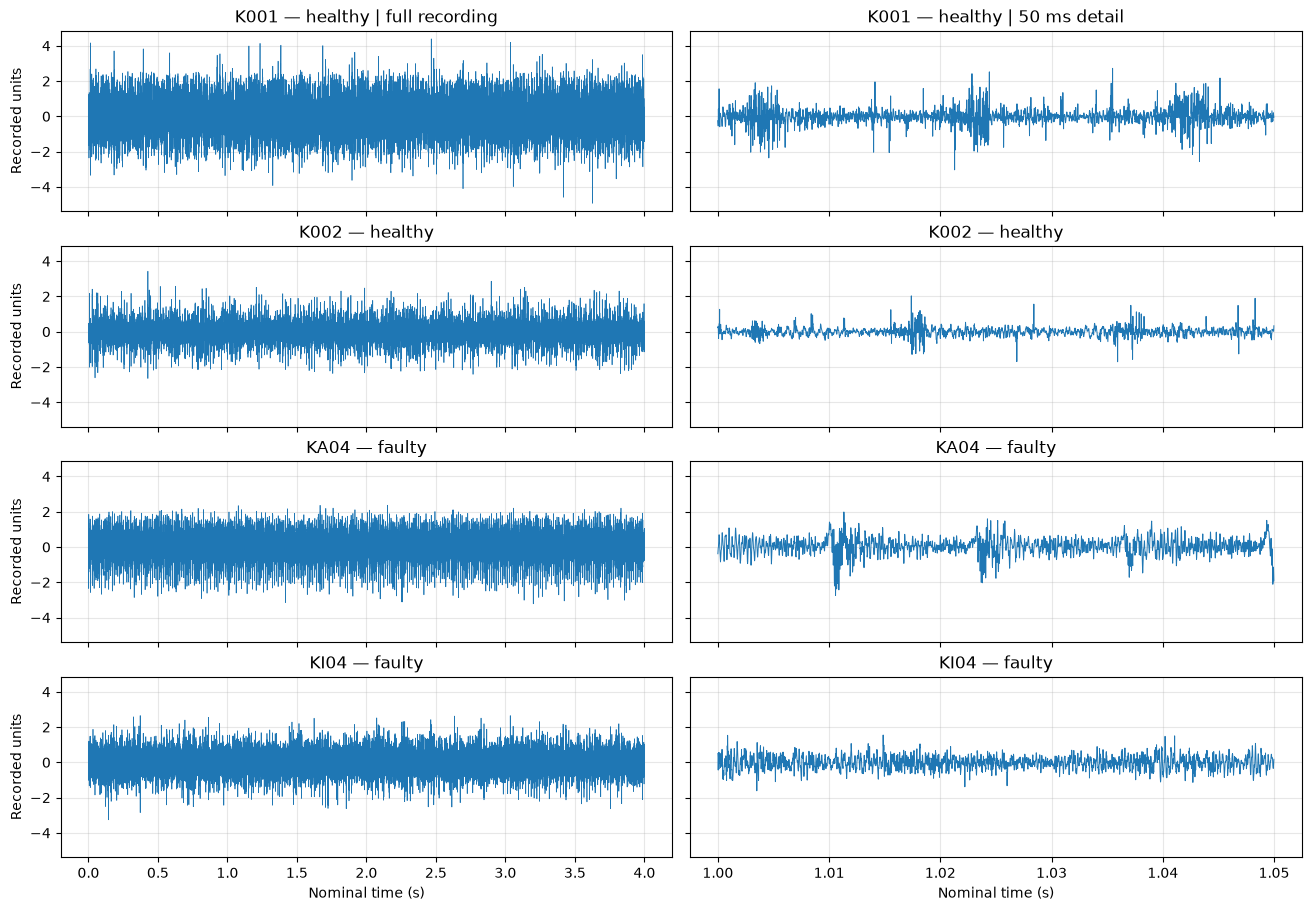

In [8]:
#: Compare full waveforms and a short detail
fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex="col", sharey=True, layout="constrained")
for i, (_, record) in enumerate(example_records.iterrows()):
    x = examples[record["recording_id"]]
    t = np.arange(x.size) / fs
    mask = (t >= 1.00) & (t < 1.05)
    axes[i, 0].plot(t, x, linewidth=0.5)
    axes[i, 1].plot(t[mask], x[mask], linewidth=0.7)
    for ax in axes[i]:
        ax.set_title(f"{record['bearing_id']} — {record['condition']}")
        ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel("Recorded units")
axes[0, 0].set_title(axes[0, 0].get_title() + " | full recording")
axes[0, 1].set_title(axes[0, 1].get_title() + " | 50 ms detail")
for ax in axes[-1]:
    ax.set_xlabel("Nominal time (s)")
plt.show()


Mean before / after centering: -0.018842242058867857 6.272735586258751e-18


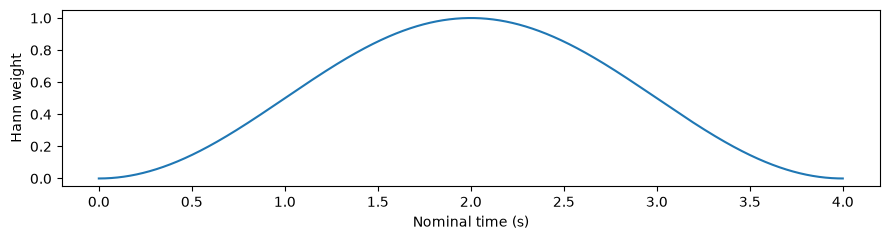

In [9]:
#Understand mean removal and the Hann window
row = example_records[example_records["bearing_id"] == "K001"].iloc[0]
x = examples[row["recording_id"]]
print("Mean before / after centering:", x.mean(), (x - x.mean()).mean())
plt.figure(figsize=(9, 2.5))
plt.plot(np.arange(x.size) / fs, hann(x.size, sym=False))
plt.xlabel("Nominal time (s)")
plt.ylabel("Hann weight")
plt.tight_layout()
plt.show()


In [10]:
#Define the FFT amplitude calculation once
def fft_amplitude(x, fs):
    n = x.size
    window = hann(n, sym=False)
    values = np.fft.rfft((x - x.mean()) * window)
    frequencies = np.fft.rfftfreq(n, d=1 / fs)
    amplitude = np.abs(values) / window.sum()
    if n % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2
    return frequencies, amplitude


In [13]:
#Calculate each example FFT once
spectra = {}
for name, signal in examples.items():
    spectra[name] = fft_amplitude(signal, fs)
f_fft, amplitude = spectra[row["recording_id"]]
print("K001 samples / FFT bins:", x.size, f_fft.size)
print("K001 bin spacing (Hz):", fs / x.size)


K001 samples / FFT bins: 256001 128001
K001 bin spacing (Hz): 0.2499990234413147


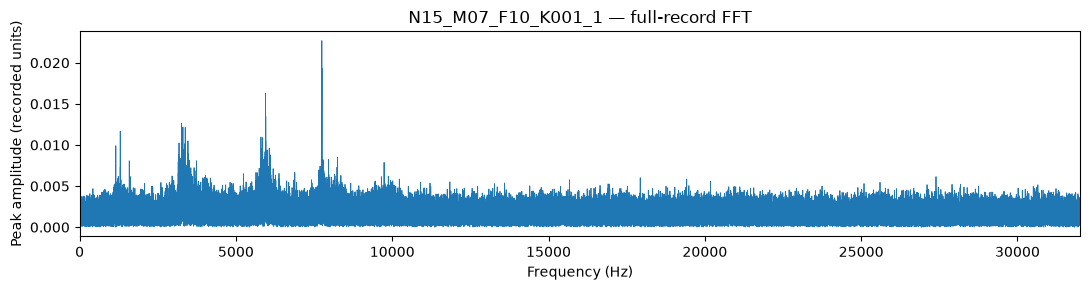

Strongest non-DC bin: 7747.72 Hz; amplitude estimate: 0.022688


In [14]:
#Inspect K001 across the full frequency range
plt.figure(figsize=(11, 3))
plt.plot(f_fft, amplitude, linewidth=0.6)
plt.xlim(0, fs / 2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Peak amplitude (recorded units)")
plt.title(f"{row['recording_id']} — full-record FFT")
plt.tight_layout()
plt.show()
peak = np.argmax(amplitude[1:]) + 1
print(f"Strongest non-DC bin: {f_fft[peak]:.2f} Hz; amplitude estimate: {amplitude[peak]:.6f}")


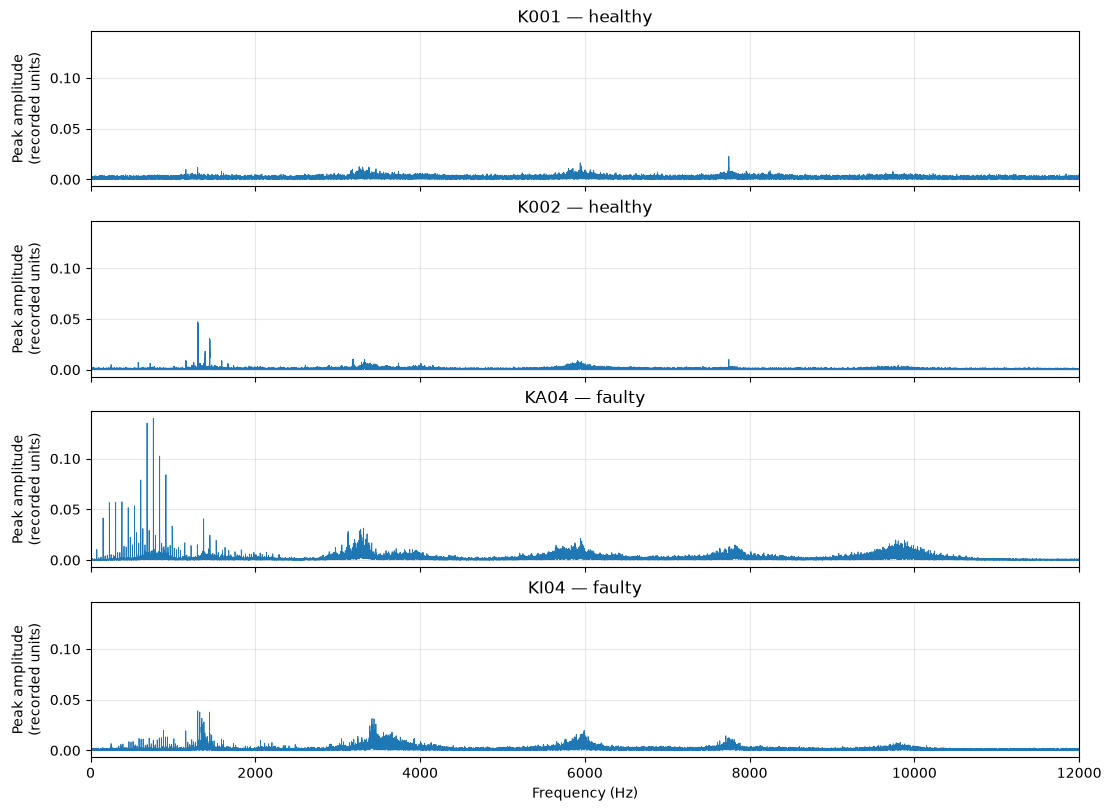

In [15]:
#Compare the four FFT spectra
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
for ax, (_, record) in zip(axes, example_records.iterrows()):
    frequencies, amplitude = spectra[record["recording_id"]]
    ax.plot(frequencies, amplitude, linewidth=0.6)
    ax.set_title(f"{record['bearing_id']} — {record['condition']}")
    ax.set_ylabel("Peak amplitude\n(recorded units)")
    ax.grid(alpha=0.3)
axes[-1].set(xlabel="Frequency (Hz)", xlim=(0, 12_000))
plt.show()


In [16]:
#Define Welch and spectrogram settings
segment_length = 8192
settings = dict(fs=fs, window="hann", nperseg=segment_length,
                noverlap=segment_length // 2, detrend="constant", scaling="density")
print("Segment duration (s):", segment_length / fs)
print("Frequency-bin spacing (Hz):", fs / segment_length)


Segment duration (s): 0.128
Frequency-bin spacing (Hz): 7.8125


In [17]:
psds = {}
for _, record in development.iterrows():
    name = record["recording_id"]
    if name in examples:
        signal = examples[name]
    else:
        signal, _ = load_vibration(raw_folder / record["relative_path"])
    assert signal.size >= segment_length, f"Recording too short for the chosen segment: {name}"
    f_psd, psds[name] = welch(signal, **settings)
print("PSDs calculated:", len(psds))


PSDs calculated: 272


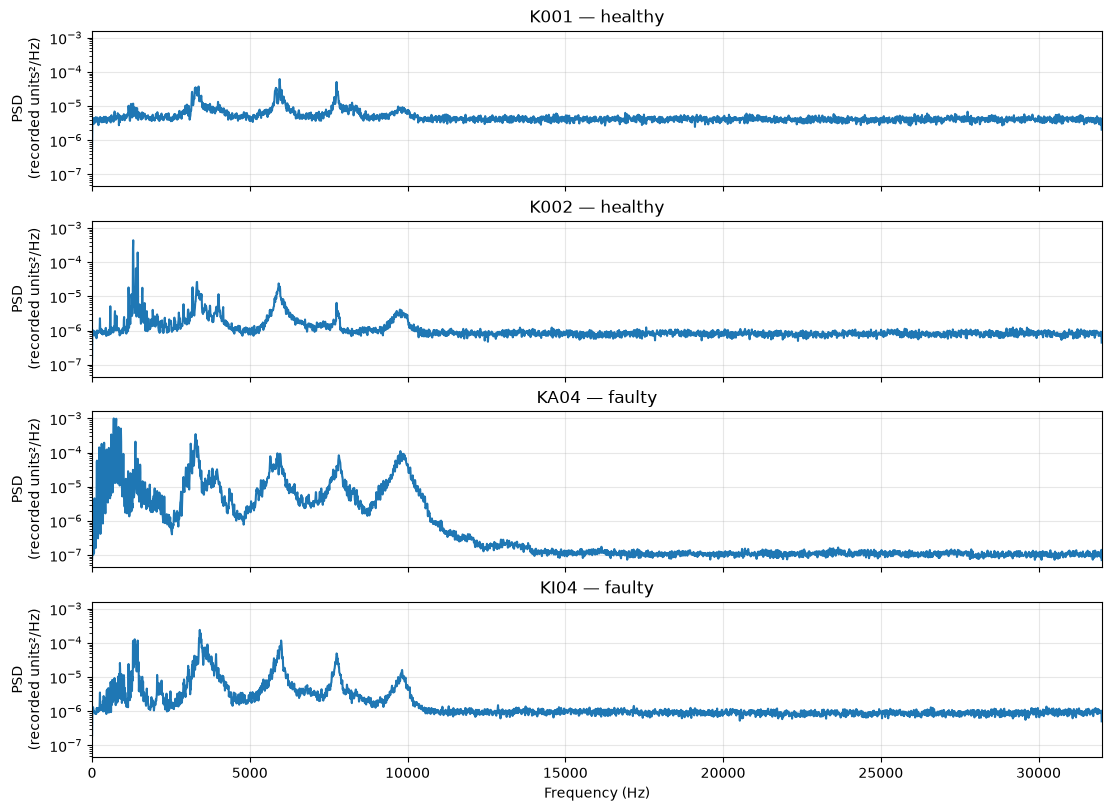

In [18]:
#Compare example PSDs over the full range
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
for ax, (_, record) in zip(axes, example_records.iterrows()):
    ax.semilogy(f_psd, psds[record["recording_id"]])
    ax.set_title(f"{record['bearing_id']} — {record['condition']}")
    ax.set_ylabel("PSD\n(recorded units²/Hz)")
    ax.grid(alpha=0.3)
axes[-1].set(xlabel="Frequency (Hz)", xlim=(0, fs / 2))
plt.show()


In [19]:
spectrograms = {}
for name, signal in examples.items():
    spectrograms[name] = spectrogram(signal, **settings, mode="psd")
frequencies, times, power = spectrograms[row["recording_id"]]
print("K001 frequency bins / time segments:", frequencies.size, times.size)
print("K001 spectrogram shape:", power.shape)


K001 frequency bins / time segments: 4097 61
K001 spectrogram shape: (4097, 61)


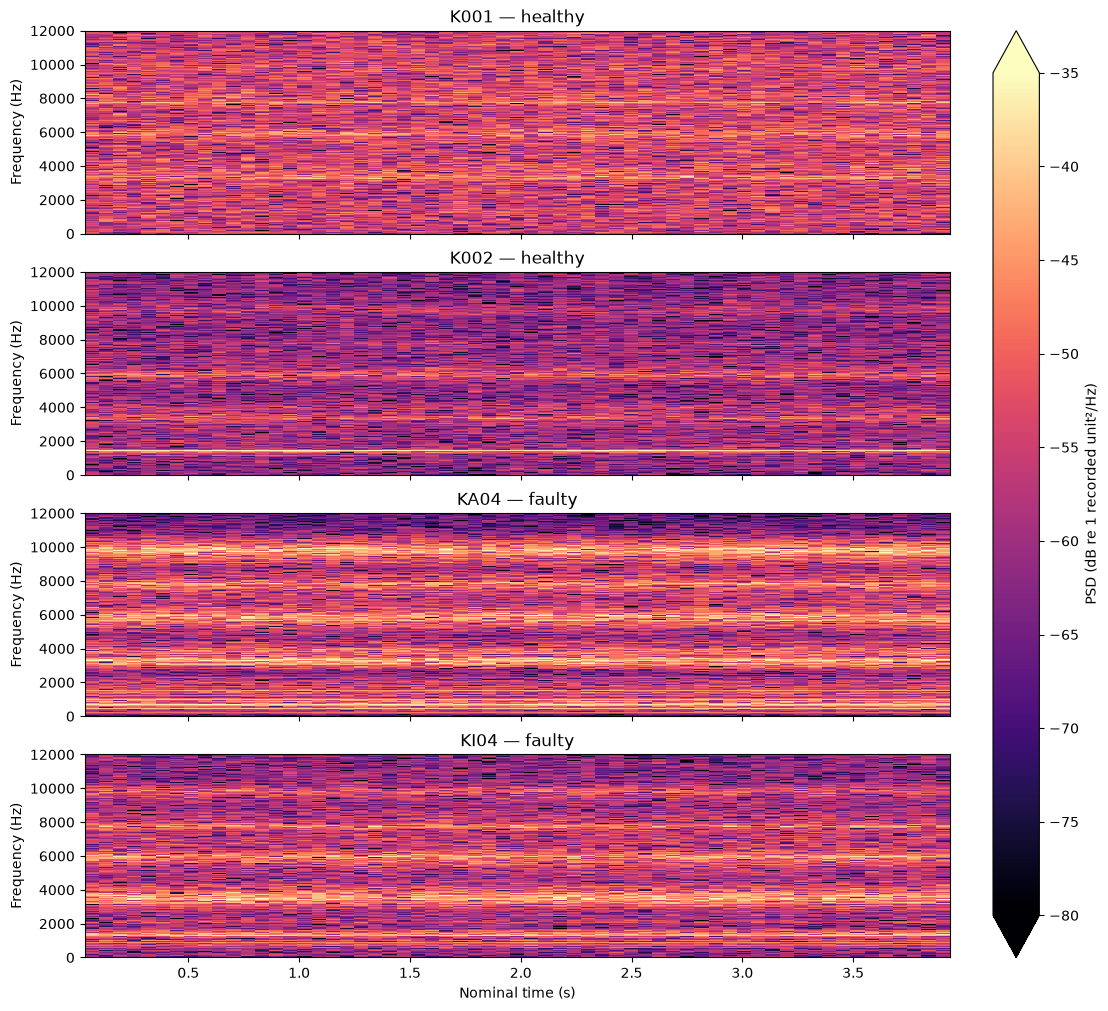

In [20]:
fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True, sharey=True, layout="constrained")
for ax, (_, record) in zip(axes, example_records.iterrows()):
    frequencies, times, power = spectrograms[record["recording_id"]]
    power_db = 10 * np.log10(np.maximum(power, 1e-12))
    mesh = ax.pcolormesh(times, frequencies, power_db, shading="auto", cmap="magma", vmin=-80, vmax=-35)
    ax.set(title=f"{record['bearing_id']} — {record['condition']}", ylabel="Frequency (Hz)", ylim=(0, 12_000))
axes[-1].set_xlabel("Nominal time (s)")
fig.colorbar(mesh, ax=axes, label="PSD (dB re 1 recorded unit²/Hz)", extend="both")
plt.show()


In [21]:
k001_ids = comparison_pool.loc[comparison_pool["bearing_id"] == "K001", "recording_id"]
matrix = np.stack([psds[name] for name in k001_ids])
median_psd = np.median(matrix, axis=0)
q25, q75 = np.percentile(matrix, [25, 75], axis=0)
print("K001 PSD matrix shape:", matrix.shape)


K001 PSD matrix shape: (16, 4097)


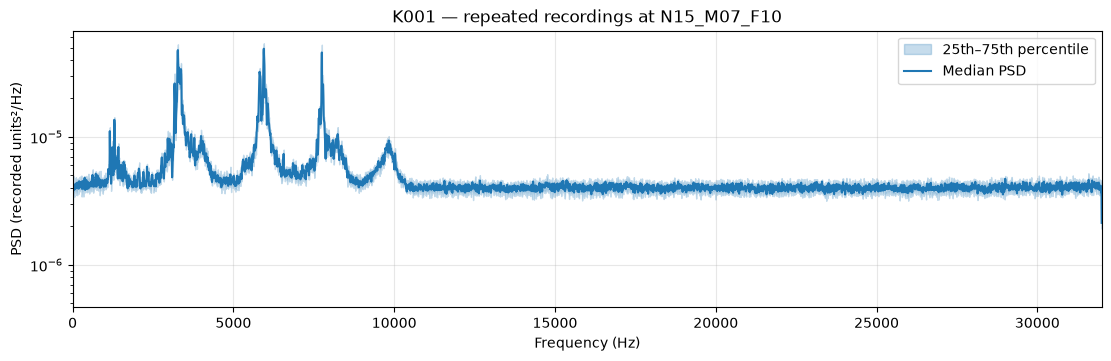

In [22]:
fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
ax.fill_between(f_psd, q25, q75, color="tab:blue", alpha=0.25, label="25th–75th percentile")
ax.semilogy(f_psd, median_psd, color="tab:blue", label="Median PSD")
ax.set(title="K001 — repeated recordings at N15_M07_F10", xlabel="Frequency (Hz)",
       ylabel="PSD (recorded units²/Hz)", xlim=(0, fs / 2))
ax.grid(alpha=0.3)
ax.legend()
plt.show()


In [23]:
lower = max(min(power.min() for power in psds.values()) / 2, 1e-12)
upper = max(max(power.max() for power in psds.values()) * 2, lower * 10)

def plot_setting(speed, torque, force):
    pool = development[(development["speed_code"] == speed) & (development["torq_code"] == torque)
                       & (development["force_code"] == force)]
    assert pool["bearing_id"].nunique() == 4, "Need all four development bearings at this setting."
    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
    for ax, (bearing, records) in zip(axes, pool.groupby("bearing_id")):
        matrix = np.stack([psds[name] for name in records["recording_id"]])
        q25, q75 = np.percentile(matrix, [25, 75], axis=0)
        ax.fill_between(f_psd, q25, q75, color="tab:blue", alpha=0.25, label="25th–75th percentile")
        ax.semilogy(f_psd, np.median(matrix, axis=0), color="tab:blue", label="Median PSD")
        ax.set_title(f"{bearing} — {records['condition'].iloc[0]} — {len(records)} recordings")
        ax.set(ylabel="PSD\n(recorded units²/Hz)", ylim=(lower, upper))
        ax.grid(alpha=0.3)
    axes[0].legend()
    axes[-1].set(xlabel="Frequency (Hz)", xlim=(0, fs / 2))
    fig.suptitle(f"{speed}_{torque}_{force} — median and middle 50%")
    plt.show()


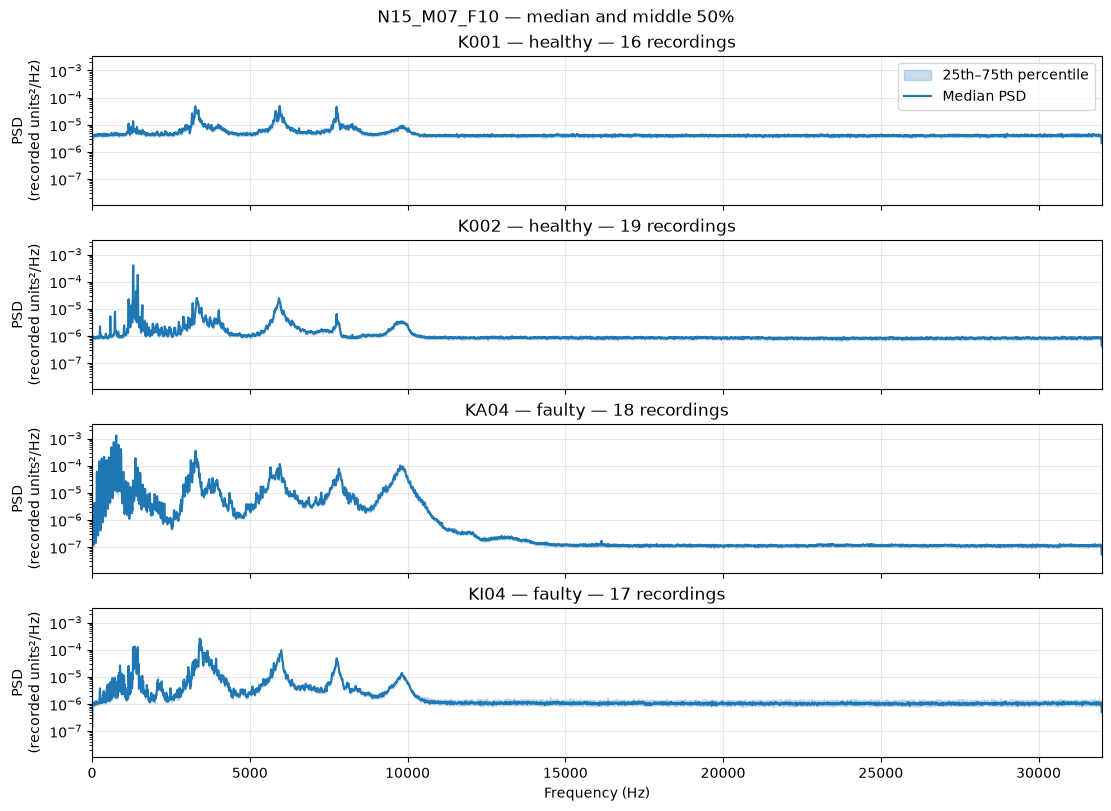

In [24]:
plot_setting("N15", "M07", "F10")


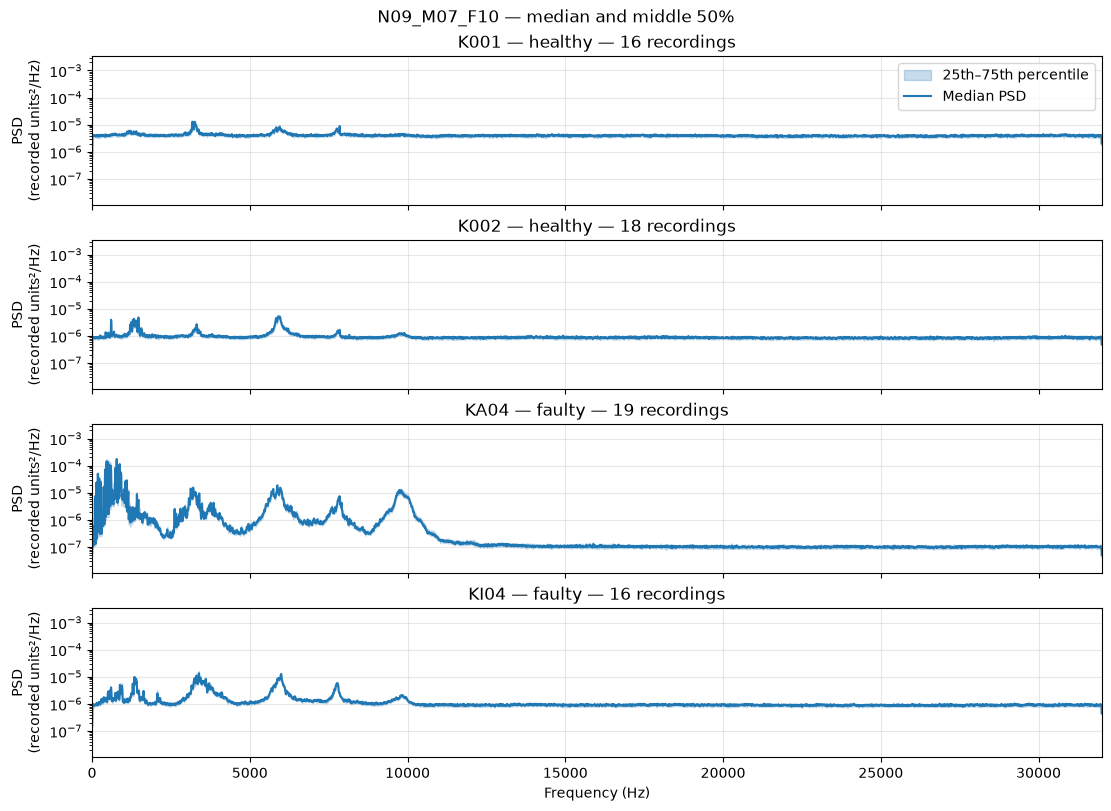

In [25]:
plot_setting("N09", "M07", "F10")


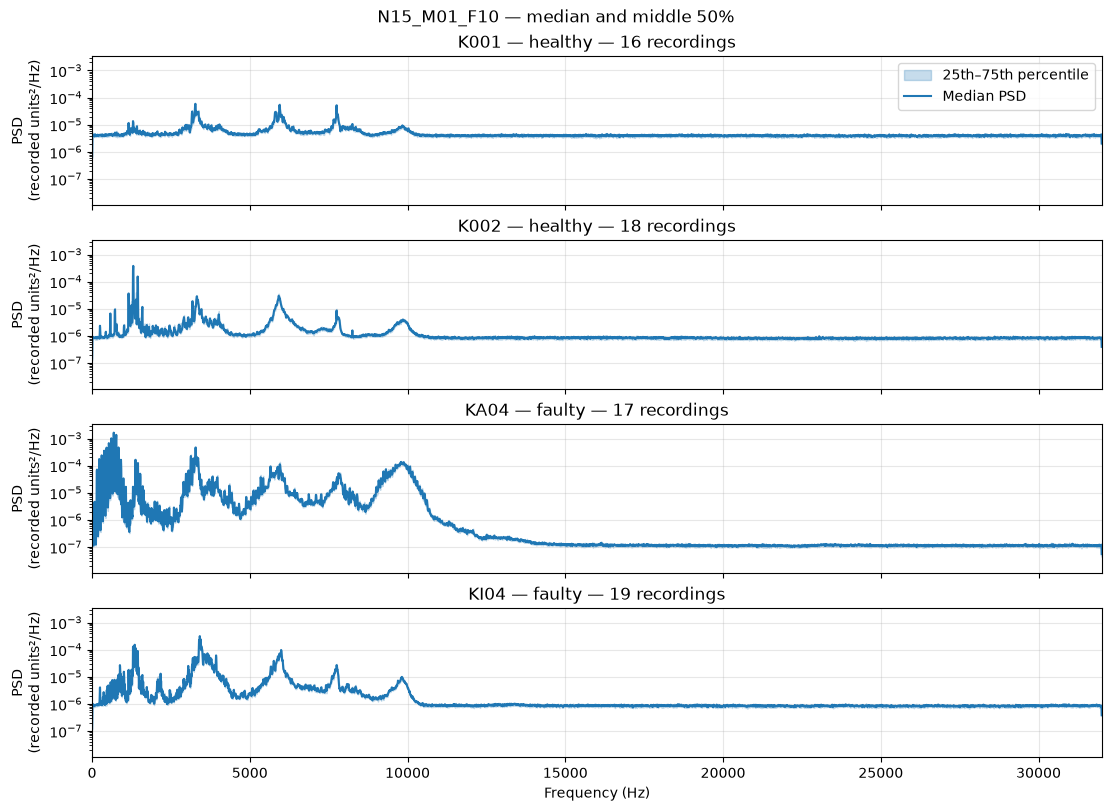

In [26]:
plot_setting("N15", "M01", "F10")
